# Import Required Libraries
Import necessary libraries for data processing, regex pattern matching, transformer models, and visualization.

In [1]:
# Import Required Libraries

# Data processing libraries
import pandas as pd
import numpy as np
from tqdm import tqdm
import os
import torch
import json

# Regex pattern matching
import re

# Transformer models
from transformers import pipeline
from datasets import Dataset

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn style for plots
sns.set(style="whitegrid")

# Set default plt font size and typeface to times
plt.rcParams.update({'font.size': 12})
plt.rcParams.update({'font.family': 'Times New Roman'})

# Load and Prepare Data
Load the JSON file containing the walkability-relevant abstracts (output of the screening pipeline), resolve the best available text field per record (contribution > abstract > introduction > text), and perform basic cleaning operations.

In [2]:
# Load the JSON file containing screened walkability abstracts using pandas
import pandas as pd

# Load data with pandas
df = pd.read_json("../data/05_filtered_walkability_applications.json")

# Print count for verification
print(f"Total articles processed: {len(df)}")

Total articles processed: 867


# Define Walkability Dimensions (Alfonzo's Hierarchy of Walking Needs)

Load the two dimension configuration artifacts:

1. `walkability_dimensions.json` — conceptual definition of each macro-dimension. In v2 this file was not loaded; only the subdomains fed the classifier. It now provides a macro-level verification step in addition to the subdomain scores.
2. `walkability_dimensions_extended.json` — operational subdomains for each macro-dimension.


In [3]:
# Conceptual definitions of macro-dimensions (v3: they are now used in practice).
with open('../data/config/walkability_dimensions.json', 'r', encoding='utf8') as f:
    macro_definitions = json.load(f)

# Operational subdomains by macro-dimension.
with open('../data/config/walkability_dimensions_extended.json', 'r', encoding='utf8') as f:
    walkability_dimensions = json.load(f)

assert set(macro_definitions) == set(walkability_dimensions), (
    "The two configs must cover exactly the same macro-dimensions."
)

# Label list = subdomains, in fixed order.
labels = [sub for subs in walkability_dimensions.values() for sub in subs]

# v2 built `flattened_dimensions[sub] = f"{sub} (part of {macro})"` and then used
# only `.keys()` — the parent context was computed and discarded. Because the verification hypothesis
# (cell below) is already a full sentence, the suffix "(part of X)" would make
# the hypothesis ungrammatical; the link to the macro-dimension is retained by the explicit mapping
# below, not embedded in the label text.
duplicates = {s for s in labels if labels.count(s) > 1}
assert not duplicates, f"Duplicate subdomain names break the mapping: {duplicates}"

# Exact mapping: subdomain -> macro-dimension.
# v2 handled this by substring matching (`if subdomain.lower() in label_lower`) inside a
# loop with `break`, which can accidentally match when one name is a prefix of another and depends
# on dictionary insertion order. Direct lookup removes both fragilities.
subdomain_to_macro = {
    sub: macro for macro, subs in walkability_dimensions.items() for sub in subs
}

print(f"Macro-dimensions: {len(walkability_dimensions)}")
print(f"Total subdomains: {len(labels)}")
for macro, subs in walkability_dimensions.items():
    print(f"  - {macro}: {len(subs)}")
print(f"Examples: {labels[:5]}")


Macro-dimensions: 5
Total subdomains: 60
  - Feasibility: 14
  - Accessibility: 12
  - Safety: 11
  - Comfort: 12
  - Pleasurability: 11
Exemplos: ['Sidewalk Provision', 'Path Continuity', 'Effective Walking Width', 'Surface Condition', 'Surface Evenness']


### What changes in v3 and why

A qualitative audit showed that dimension errors are not uniform: Pleasurability concentrates false positives, while Safety concentrates PARTIAL cases — dimensions invoked rhetorically and rarely measured. Both arise from the same issue in v2: the classification hypothesis was too topical.

```
v2:  "This text is about Streetscape Aesthetics."
```

This formulation is true for any article that talks about street aesthetics, even when the study does not measure it at all — which is exactly the definition of PARTIAL in the extraction rubric. v3 rewrites the hypothesis to assert measurement of an environmental attribute, the same distinction used to separate dimensions from outcomes in the notebook 05 scope rules:

```
v3:  "This study measures streetscape aesthetics as an attribute of the pedestrian environment."
```

In addition, v3 adds a macro-level verification step using the conceptual definitions in `walkability_dimensions.json`. In v2, the macro-dimension was assigned by the maximum subdomain score: a single subdomain firing in isolation was enough to mark the whole dimension. Requiring the construct to hold at the macro level penalizes isolated triggers without penalizing articles that genuinely measure the dimension.

> Subdomain lists follow Alfonzo's hierarchy and the facets of the consolidated audit instruments (MAPS, PEDS, SWEAT, NEWS). Three items from v2 were removed because they name perception or outcome rather than environmental attribute: `Perceived Safety`, `Pedestrian Crash Exposure`, and `Visual Quality`. `Crime and Personal Security` was split into `Physical Disorder and Incivilities` and `Security Infrastructure`, both observable in the environment.

### v4 — text field

`introduction` was replaced by priority `contribution` (with fallback). A false-negative audit found 10/11 verified genuine positives missed, concentrated in technical engineering/CV/sensor papers whose `introduction` is a generic literature review and whose `contribution` states directly what was measured.

### v5 — margin against outcome/covariate bias

After v4, a second audit (marginal-score band, 25 records) found **19/25 (76%) false positives**, and the dominant pattern was always the same: a study whose research object is an OUTCOME (physical activity, obesity, mortality, gentrification) that describes in methodological detail how it measured the built environment. This makes the text score highly on "this measures X environmental attribute" even though it is fundamentally about the outcome, not the attribute. **Thresholding does not solve this**: it measures confidence in attribute detection, not whether the study's central research question is the attribute itself. Those are orthogonal axes, and tightening the cut in the first axis does not fix the second.

The `05` notebook already has this mechanism — `HARD_NEGATIVE_ANCHORS`, semantic NLI margin against competing hypotheses — but there was no equivalent in `06_1`. v5 imports the same principle (**not** the literal keyword gate, which is sensor-specific and was explicitly discarded for dimension classification): a second verification pass with hypotheses describing the pattern of "environment as a covariate of another outcome" rather than "environment as the measured object". The final score for each macro-dimension becomes a margin — positive signal minus the strongest negative signal — instead of only the average of the two positive signals.


# Build Transformer Model
Initialize a pre-trained transformer model and set up a zero-shot, multi-label classification approach.

In [4]:
# Build Transformer Model for Zero-Shot Classification
# model = "facebook/bart-large-mnli"
model = "MoritzLaurer/deberta-v3-large-zeroshot-v2.0-c"

os.environ["TOKENIZERS_PARALLELISM"] = "false"

print("CUDA available:", torch.cuda.is_available())
print("MPS available:", torch.backends.mps.is_available())

if torch.backends.mps.is_available():
    device = "mps"
    print("Using MPS (Metal Performance Shaders)")
elif torch.cuda.is_available():
    device = 0
    print("Using CUDA GPU")
else:
    device = -1
    print("Using CPU")

device = torch.device(device)

try:
    classifier = pipeline(
        "zero-shot-classification", model=model, device=device, multi_label=True
    )
    print("Classifier initialized successfully")
except Exception as e:
    print(f"Error initializing with {device}, falling back to CPU")
    device = -1
    classifier = pipeline(
        "zero-shot-classification", model=model, device=device, multi_label=True
    )


# ==================================================================
# Verification hypotheses
# ==================================================================

# Subdomain level. v2 used "This text is about {}." — topic, not measurement.
SUBDOMAIN_HYPOTHESIS = "This study measures {} as an attribute of the pedestrian environment."
subdomain_label_text = {sub: sub.lower() for sub in labels}
label_text_to_subdomain = {v: k for k, v in subdomain_label_text.items()}
SUBDOMAIN_LABEL_LIST = [subdomain_label_text[s] for s in labels]
assert len(label_text_to_subdomain) == len(labels), "label collision after lowercasing"

# Macro level. The full definitions in `walkability_dimensions.json` are too long
# to serve as a direct NLI hypothesis (the model degrades with hypotheses longer than ~20
# words). A short paraphrase per macro-dimension is used instead, derived from the definition — which
# remains the normative source cited in the paper.
MACRO_HYPOTHESIS = "This study measures {} of the pedestrian environment."
MACRO_SHORT_FORM = {
    "Feasibility": "whether walking is physically provided for and possible",
    "Accessibility": "how reachable destinations are on foot",
    "Safety": "protection from traffic, crime, and hazards while walking",
    "Comfort": "the physical and environmental ease of walking",
    "Pleasurability": "the visual and experiential quality of the streetscape",
}
missing_short = set(macro_definitions) - set(MACRO_SHORT_FORM)
assert not missing_short, f"Missing short paraphrase for: {missing_short}"
macro_label_text = {m: MACRO_SHORT_FORM[m] for m in macro_definitions}
macro_text_to_name = {v: k for k, v in macro_label_text.items()}
MACRO_LABEL_LIST = [macro_label_text[m] for m in walkability_dimensions]

# ------------------------------------------------------------------
# v5 — negative anchors: margin against "environment used as a covariate of another outcome"
# ------------------------------------------------------------------
# Same principle as the HARD_NEGATIVE_ANCHORS in 05 (semantic NLI margin against
# competing hypotheses), not the literal keyword gate — that is specific to
# sensor classification and was discarded for dimension classification because the walkability construct is inferred,
# not explicitly stated by term. Here the second hypothesis describes the dominant false-positive pattern
# found in the marginal-band audit: a study whose research object is
# an outcome (physical activity, health, behavior), where the built environment is described only as
# a covariate/predictor, not as the object being measured.
#
# One pass shared across all macro-dimensions (not one anchor per dimension):
# the pattern "this is an outcome study where the environment is only a covariate" is a
# property of the article as a whole, not of any specific dimension.
DIMENSION_HARD_NEGATIVES = [
    # Rule 4 — health behavior/outcome treated as the research object.
    # v6: reescrita. A v5 usava "...associated with, predicts, or MEDIATES a physical
    # activity...outcome, RATHER THAN measuring the environment itself..." -- essa
    # the anchor alone caused 92% of all negative triggers in the corpus and suppressed
    # 44% of the 45 confirmed positives in real.json (including clear misfires,
    # como um artigo cujo "mediation model" mede o papel do comportamento visual sobre
    # perceived walkability -- nothing to do with physical activity/health). Two issues in
    # the old wording: (1) "mediates" is a generic statistical-method term that fires in
    # any study with a mediation model, regardless of the mediated outcome; (2) the
    # contrastive clause "rather than" is the type of negation that NLI notoriously does not
    # handle well -- the model tends to react to the vocabulary in the first half of the sentence
    # and ignore the caveat in the second half. The rewrite states the central outcome
    # diretamente, sem "mediates" e sem estrutura contrastiva.
    "This study's primary research outcome is physical activity, health status, or "
    "behavior; the built environment is used only as a predictor of that outcome.",
    # Rule D — pre-existing index used only as a covariate
    "This study uses a pre-existing walkability index, audit score, or environmental "
    "measure only as a covariate or predictor in an analysis of an unrelated outcome, "
    "without describing new measurement of the environment.",
    # Rule 3 — wrong inferential construct (collision/crime risk, not walkability)
    "This study investigates crash risk, crime risk, or property values as the outcome "
    "of interest, using environmental data only as a predictor of that risk.",
    # Rule 3 — robot/vehicle navigation, wrong population
    "This study develops or evaluates a navigation, routing, or delivery system for "
    "robots, vehicles, or logistics operations, not a measurement of the pedestrian "
    "built environment.",
]
DIMENSION_HARD_NEGATIVE_HYPOTHESIS = "{}"  # the anchors are already complete sentences

# DIAGNOSTIC-ONLY threshold, used solely to report "how many records have
# negative_score above X" in print statements further down. It does NOT gate
# anything in the actual scoring -- combine_macro_score() always applies the
# negative margin (scaled by NEGATIVE_MARGIN_WEIGHT above), regardless of this
# value. Overwritten by the calibration cell below for reporting purposes only.
NEGATIVE_ANCHOR_FIRE_THRESHOLD = 0.5

# Combination of signals in the final macro-dimension score.
#   "max"         = v2 behavior (only the best subdomain)
#   "mean"        = average of the best subdomain and macro verification (v3/v4 default)
#   "min"         = exige os dois sinais fortes (mais conservador)
#   "mean_margin" = average of positive signals minus the strongest negative anchor (v5 default)
MACRO_COMBINATION = "mean_margin"


# v8 -- damped margin weight. combine_macro_score used to subtract negative_score
# 1:1 from the positive signal. That is a full-strength subtraction: a negative_score
# of 0.78 wipes out almost the entire 0-1 positive range in one shot, regardless of
# how strong the positive evidence was. NEGATIVE_ANCHOR_FIRE_THRESHOLD (below, in the
# calibration cell) does NOT gate this -- it is diagnostic-only, used solely in the
# print statements that count "how many records have negative_score above X". The
# thing that actually decides whether a record clears the bar is CALIBRATED_THRESHOLD,
# computed later against real.json to hit TARGET_DIMENSION_RECALL. Softening the
# margin here, rather than hunting for a better firing threshold on a 55-example set,
# is the fix that actually changes pipeline behaviour.
#
# NEGATIVE_MARGIN_WEIGHT scales the subtraction: 1.0 = full strength (v5/v6/v7
# behaviour), 0.0 = negative anchors have no effect at all. 0.5 is a starting point,
# not a validated value -- re-check the real.json rejection rate and a fresh
# marginal-band audit after running with this weight, and adjust if needed.
NEGATIVE_MARGIN_WEIGHT = 0.5


def combine_macro_score(best_subdomain_score, macro_direct_score, negative_score=0.0):
    if MACRO_COMBINATION == "max":
        return best_subdomain_score
    if MACRO_COMBINATION == "min":
        return min(best_subdomain_score, macro_direct_score)
    positive = (best_subdomain_score + macro_direct_score) / 2
    if MACRO_COMBINATION == "mean_margin":
        return positive - NEGATIVE_MARGIN_WEIGHT * negative_score
    return positive  # "mean"


def macro_scores_from_parts(subdomain_scores, macro_direct, negative_score=0.0):
    """subdomain_scores: dict sub->score; macro_direct: dict macro->score.

    `negative_score` is unique per record (not per macro-dimension) — it reflects how much
    the article as a whole looks like an outcome/covariate study, and it is applied
    equally to all candidate macro-dimensions in that record.
    """
    out = {}
    for macro, subs in walkability_dimensions.items():
        best_sub = max((subdomain_scores.get(s, 0.0) for s in subs), default=0.0)
        out[macro] = combine_macro_score(best_sub, macro_direct.get(macro, 0.0), negative_score)
    return out


def get_negative_score(text):
    """Highest entailment score among negative anchors -- how much the article looks like an outcome/covariate study rather than a measurement study."""
    res = classifier(
        text,
        candidate_labels=DIMENSION_HARD_NEGATIVES,
        hypothesis_template=DIMENSION_HARD_NEGATIVE_HYPOTHESIS,
        multi_label=True,
    )
    return max(res["scores"])


def classify_sentences(sentences, labels):
    """Record-by-record classification (used in the test cell below)."""
    results = []
    for sentence in tqdm(sentences):
        if sentence:
            try:
                result = classifier(
                    sentence,
                    candidate_labels=[subdomain_label_text[s] for s in labels],
                    hypothesis_template=SUBDOMAIN_HYPOTHESIS,
                    multi_label=True,
                )
                results.append(result)
            except Exception as e:
                print(f"Error processing sentence: {str(e)}")
                results.append(None)
    return results


CUDA available: True
MPS available: False
Using CUDA GPU


Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

Classifier initialized successfully


In [5]:
# Quick test: three cases.
# probe: speaks of aesthetics without measuring them (already tested in v3/v4).
# probe_outcome: exactly the dominant FP pattern from the marginal-band audit --
#   describes a built-environment audit in methodological detail, but the research object is
#   the physical-activity outcome.
probe = ("Streetscape aesthetics are widely believed to encourage walking. This study "
         "measures sidewalk width and surface condition from street-level imagery to "
         "audit the pedestrian network of three districts.")
probe_outcome = ("We used a validated microscale audit tool to objectively measure "
                  "sidewalk width, crossing density, and street lighting in 40 "
                  "neighborhoods. Accelerometer-derived physical activity was the "
                  "primary outcome; we examined whether built environment audit scores "
                  "predicted moderate-to-vigorous physical activity in older adults.")

for name, txt in [("v2 (topic)      ", probe), ("v3 (measurement) ", probe)]:
    res = classifier(
        txt,
        candidate_labels=[subdomain_label_text[s] for s in labels],
        hypothesis_template="This text is about {}." if "v2" in name else SUBDOMAIN_HYPOTHESIS,
        multi_label=True,
    )
    top = list(zip(res["labels"], res["scores"]))[:4]
    print(f"[{name}] " + ", ".join(f"{label_text_to_subdomain[l]}={s:.3f}" for l, s in top))

print()
for name, txt in [("aesthetics without measurement", probe), ("audit->PA outcome", probe_outcome)]:
    sub_res = classifier(txt, candidate_labels=SUBDOMAIN_LABEL_LIST,
                          hypothesis_template=SUBDOMAIN_HYPOTHESIS, multi_label=True)
    macro_res = classifier(txt, candidate_labels=MACRO_LABEL_LIST,
                            hypothesis_template=MACRO_HYPOTHESIS, multi_label=True)
    sub_scores = dict(zip([label_text_to_subdomain[l] for l in sub_res["labels"]], sub_res["scores"]))
    macro_direct = dict(zip([macro_text_to_name[l] for l in macro_res["labels"]], macro_res["scores"]))
    neg = get_negative_score(txt)
    ms_no_margin = macro_scores_from_parts(sub_scores, macro_direct, negative_score=0.0)
    ms_margin = macro_scores_from_parts(sub_scores, macro_direct, negative_score=neg)
    print(f"[{name}] negative_score={neg:.3f}")
    print(f"  without margin : {[(m, round(s,3)) for m,s in sorted(ms_no_margin.items(), key=lambda kv:-kv[1])[:2]]}")
    print(f"  with margin : {[(m, round(s,3)) for m,s in sorted(ms_margin.items(), key=lambda kv:-kv[1])[:2]]}")

# Expected: "audit->PA outcome" should have a high negative_score (it matches the Rule 4 anchor), and
# the final margin-adjusted score should drop noticeably relative to the no-margin version -- exactly
# the case flagged by the marginal-band audit as an FP.


[v2 (topic)      ] Streetscape Aesthetics=0.994, Pedestrian Space Adequacy=0.990, Sidewalk Provision=0.983, Surface Condition=0.938
[v3 (measurement)] Sidewalk Provision=0.990, Streetscape Aesthetics=0.987, Surface Condition=0.986, Pedestrian Space Adequacy=0.985

[aesthetics without measurement] negative_score=0.040
  without margin : [('Comfort', 0.981), ('Feasibility', 0.96)]
  with margin : [('Comfort', 0.961), ('Feasibility', 0.939)]
[auditoria->PA outcome] negative_score=0.775
  without margin : [('Feasibility', 0.85), ('Comfort', 0.82)]
  with margin : [('Feasibility', 0.463), ('Comfort', 0.433)]


In [6]:
import numpy as np

with open('../data/dimension_rule_calibration.json', 'r', encoding='utf8') as f:
    calib_records = json.load(f)

print(f"Loaded {len(calib_records)} hand-labelled records "
      f"({sum(r['label']==1 for r in calib_records)} genuine measurement / "
      f"{sum(r['label']==0 for r in calib_records)} outcome-covariate-or-wrong-construct)")

# Candidate phrasings for the Rule-4 anchor (behavior/health-outcome pattern). The other
# three anchors (index-as-covariate, crash/crime, robot/vehicle) are held fixed -- the
# manual audits never found evidence they were miscalibrated, only anchor #1 was.
RULE4_CANDIDATES = {
    "v5_broad_contrastive": (
        "This study analyzes how a built-environment or walkability measure is associated "
        "with, predicts, or mediates a physical activity, health, or behavioral outcome, "
        "rather than measuring the environment itself as the object of the study."
    ),
    "v6_narrow_conjunctive": (
        "This study's primary research outcome is physical activity, health status, or "
        "behavior; the built environment is used only as a predictor of that outcome."
    ),
    "v7_broad_no_contrast": (
        "This study's primary research question concerns physical activity, health, or "
        "behavior as the outcome, examining how the built environment predicts, moderates, "
        "or is associated with that outcome."
    ),
    "v7_simple_declarative": (
        "This is primarily a study of physical activity, health, or behavior, using the "
        "built environment only as an explanatory variable."
    ),
    "v7_short": (
        "The main outcome of this study is physical activity or health, not a property of "
        "the built environment."
    ),
}

FIXED_ANCHORS = DIMENSION_HARD_NEGATIVES[1:]  # index-covariate, crash/crime, robot/vehicle


def negative_score_for(text, rule4_text):
    """Max entailment score across the candidate Rule-4 anchor plus the three fixed
    anchors -- mirrors how `get_negative_score` is actually used in production."""
    res = classifier(
        text,
        candidate_labels=[rule4_text] + FIXED_ANCHORS,
        hypothesis_template=DIMENSION_HARD_NEGATIVE_HYPOTHESIS,
        multi_label=True,
    )
    return max(res["scores"])


def roc_auc(scores, labels_are_negative):
    """AUC without sklearn: probability a random label=0 record scores higher than a
    random label=1 record. labels_are_negative: True where label==0 (should score high)."""
    pos = [s for s, neg in zip(scores, labels_are_negative) if neg]
    negv = [s for s, neg in zip(scores, labels_are_negative) if not neg]
    if not pos or not negv:
        return float("nan")
    wins = sum((p > n) + 0.5 * (p == n) for p in pos for n in negv)
    return wins / (len(pos) * len(negv))


texts = [r["text"] for r in calib_records]
is_neg = [r["label"] == 0 for r in calib_records]

results = {}
for name, candidate_text in RULE4_CANDIDATES.items():
    scores = [negative_score_for(t, candidate_text) for t in tqdm(texts, desc=name)]
    auc = roc_auc(scores, is_neg)
    # Precision/recall at the production firing threshold (0.5), for interpretability.
    pred_neg = [s > 0.5 for s in scores]
    tp = sum(p and n for p, n in zip(pred_neg, is_neg))
    fp = sum(p and not n for p, n in zip(pred_neg, is_neg))
    fn = sum(not p and n for p, n in zip(pred_neg, is_neg))
    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")
    results[name] = {"auc": auc, "precision@0.5": precision, "recall@0.5": recall,
                      "fires@0.5": sum(pred_neg), "scores": scores}
    print(f"{name:24s} AUC={auc:.3f}  precision@0.5={precision:.2f}  "
          f"recall@0.5={recall:.2f}  fires={sum(pred_neg)}/{len(texts)}")

best_name = max(results, key=lambda k: results[k]["auc"])
print(f"\nBest by AUC: {best_name} (AUC={results[best_name]['auc']:.3f})")

# Also pick the firing threshold that maximizes Youden's J (recall - false-positive-rate)
# for the winning candidate, instead of assuming 0.5 is right.
best_scores = results[best_name]["scores"]
candidate_thresholds = sorted(set(best_scores))
best_j, best_thresh = -1, 0.5
for th in candidate_thresholds:
    pred = [s > th for s in best_scores]
    tp = sum(p and n for p, n in zip(pred, is_neg))
    fn = sum(not p and n for p, n in zip(pred, is_neg))
    fp = sum(p and not n for p, n in zip(pred, is_neg))
    tn = sum(not p and not n for p, n in zip(pred, is_neg))
    tpr = tp / (tp + fn) if (tp + fn) else 0
    fpr = fp / (fp + tn) if (fp + tn) else 0
    j = tpr - fpr
    if j > best_j:
        best_j, best_thresh = j, th
print(f"Youden-optimal firing threshold for {best_name}: {best_thresh:.3f} (J={best_j:.3f})")
print("NEGATIVE_ANCHOR_FIRE_THRESHOLD below is used ONLY for the reporting prints "
      "further down (\"N records have negative_score above X\") -- it does not "
      "affect scoring. The actual damping is NEGATIVE_MARGIN_WEIGHT, set separately "
      "in the cell above.")

# Wire the winning anchor and threshold back into the pipeline.
DIMENSION_HARD_NEGATIVES[0] = RULE4_CANDIDATES[best_name]
NEGATIVE_ANCHOR_FIRE_THRESHOLD = float(best_thresh)
print(f"\nDIMENSION_HARD_NEGATIVES[0] set to the '{best_name}' phrasing for the rest of "
      f"this run.")


Loaded 55 hand-labelled records (22 genuine measurement / 33 outcome-covariate-or-wrong-construct)


v5_broad_contrastive: 100%|██████████| 55/55 [00:58<00:00,  1.06s/it]


v5_broad_contrastive     AUC=0.760  precision@0.5=0.85  recall@0.5=0.67  fires=26/55


v6_narrow_conjunctive: 100%|██████████| 55/55 [00:51<00:00,  1.07it/s]


v6_narrow_conjunctive    AUC=0.534  precision@0.5=0.67  recall@0.5=0.06  fires=3/55


v7_broad_no_contrast: 100%|██████████| 55/55 [00:53<00:00,  1.04it/s]


v7_broad_no_contrast     AUC=0.803  precision@0.5=0.86  recall@0.5=0.58  fires=22/55


v7_simple_declarative: 100%|██████████| 55/55 [00:44<00:00,  1.22it/s]


v7_simple_declarative    AUC=0.526  precision@0.5=0.75  recall@0.5=0.09  fires=4/55


v7_short: 100%|██████████| 55/55 [00:51<00:00,  1.07it/s]

v7_short                 AUC=0.518  precision@0.5=0.67  recall@0.5=0.06  fires=3/55

Best by AUC: v7_broad_no_contrast (AUC=0.803)
Youden-optimal firing threshold for v7_broad_no_contrast: 0.220 (J=0.561)
NEGATIVE_ANCHOR_FIRE_THRESHOLD below is used ONLY for the reporting prints further down ("N records have negative_score above X") -- it does not affect scoring. The actual damping is NEGATIVE_MARGIN_WEIGHT, set separately in the cell above.

DIMENSION_HARD_NEGATIVES[0] set to the 'v7_broad_no_contrast' phrasing for the rest of this run.


# Classify Abstracts


In [7]:
# ------------------------------------------------------------------
# Text field: explicit fallback, contribution first (same priority as 05)
# ------------------------------------------------------------------
DIMENSION_TEXT_FIELDS = ["contribution", "abstract", "introduction", "text"]

available = [c for c in DIMENSION_TEXT_FIELDS if c in df.columns]
if not available:
    raise KeyError(
        f"No usable text field in {DIMENSION_TEXT_FIELDS}; "
        f"available columns: {list(df.columns)}"
    )

def resolve_text(row):
    for c in available:
        val = row.get(c)
        if isinstance(val, str) and val.strip():
            return val.strip(), c
    return "", None

resolved = df.apply(resolve_text, axis=1)
df = df.copy()
df["dimension_text"] = [t for t, _ in resolved]
df["dimension_text_field"] = [c for _, c in resolved]

df_filtered = df[df["dimension_text"].str.strip().astype(bool)].copy()

print(f"\nClassifying {len(df_filtered)} abstracts...")
print("Campo usado por registro:")
print(df_filtered["dimension_text_field"].value_counts().to_string())

dataset = Dataset.from_pandas(df_filtered[["dimension_text"]])


def classify_batch(batch):
    """Three batch passes: subdomains, macro-dimensions, negative anchors (v5).

    The macro pass is cheap (5 labels versus 60) and provides the second signal that
    prevents a macro-dimension from being assigned on the basis of a single subdomain firing
    in isolation. The negative-anchor pass (4 labels) is the margin against the
    dominant FP pattern found in the audit: environment treated as a covariate
    of an outcome, not as the measured object.
    """
    try:
        sub_res = classifier(
            batch["dimension_text"],
            candidate_labels=SUBDOMAIN_LABEL_LIST,
            hypothesis_template=SUBDOMAIN_HYPOTHESIS,
            multi_label=True,
            batch_size=8,
        )
        macro_res = classifier(
            batch["dimension_text"],
            candidate_labels=MACRO_LABEL_LIST,
            hypothesis_template=MACRO_HYPOTHESIS,
            multi_label=True,
            batch_size=8,
        )
        negative_res = classifier(
            batch["dimension_text"],
            candidate_labels=DIMENSION_HARD_NEGATIVES,
            hypothesis_template=DIMENSION_HARD_NEGATIVE_HYPOTHESIS,
            multi_label=True,
            batch_size=8,
        )

        # The pipeline reorders labels by score; remaps them back to the original name.
        batch["classification_labels"] = [
            [label_text_to_subdomain[l] for l in r["labels"]] for r in sub_res
        ]
        batch["classification_scores"] = [r["scores"] for r in sub_res]
        batch["macro_direct_scores"] = [
            {macro_text_to_name[l]: s for l, s in zip(r["labels"], r["scores"])}
            for r in macro_res
        ]
        batch["negative_score"] = [max(r["scores"]) for r in negative_res]
        batch["negative_labels"] = [
            r["labels"][r["scores"].index(max(r["scores"]))] for r in negative_res
        ]
        return batch
    except Exception as e:
        print(f"Error processing batch: {str(e)}")
        return batch


processed_dataset = dataset.map(
    classify_batch,
    batched=True,
    batch_size=16,
    desc="Classifying",
)

results_df = processed_dataset.to_pandas()

df_filtered["classification_labels"] = results_df["classification_labels"].tolist()
df_filtered["classification_scores"] = results_df["classification_scores"].tolist()
df_filtered["macro_direct_scores"] = results_df["macro_direct_scores"].tolist()
df_filtered["negative_score"] = results_df["negative_score"].tolist()
df_filtered["negative_labels"] = results_df["negative_labels"].tolist()

# Combined macro score (best subdomain + macro verification − negative margin),
# computed once and reused in assignment and diagnostics.
df_filtered["macro_scores"] = [
    macro_scores_from_parts(dict(zip(lbls, scs)), dict(md), negative_score=neg)
    for lbls, scs, md, neg in zip(
        df_filtered["classification_labels"],
        df_filtered["classification_scores"],
        df_filtered["macro_direct_scores"],
        df_filtered["negative_score"],
    )
]

valid_results = df_filtered["classification_labels"].notna().sum()
print(f"\nSuccessfully classified {valid_results} out of {len(df_filtered)} records")
print(f"Macro combination in use: MACRO_COMBINATION = {MACRO_COMBINATION!r}")

# Diagnostic: how many records have a high negative_score (using the calibrated
# firing threshold, not a hardcoded 0.5) -- candidates for
# outcome-study pattern, irrespective of whether they ultimately received a dimension.
high_negative = (df_filtered["negative_score"] > NEGATIVE_ANCHOR_FIRE_THRESHOLD).sum()
print(f"\nRecords with negative_score above threshold ({NEGATIVE_ANCHOR_FIRE_THRESHOLD:.3f}, "
      f"strong outcome/covariate pattern): "
      f"{high_negative} ({high_negative/len(df_filtered)*100:.1f}%)")
print("Distribution by fired anchor (among these):")
print(df_filtered.loc[df_filtered["negative_score"] > NEGATIVE_ANCHOR_FIRE_THRESHOLD, "negative_labels"]
      .value_counts().to_string())



Classifying 867 abstracts...
Campo usado por registro:
dimension_text_field
contribution    867


Classifying:   0%|          | 0/867 [00:00<?, ? examples/s]


Successfully classified 867 out of 867 records
Macro combination in use: MACRO_COMBINATION = 'mean_margin'

Records with negative_score above threshold (0.220, strong outcome/covariate pattern): 502 (57.9%)
Distribution by fired anchor (among these):
negative_labels
This study's primary research question concerns physical activity, health, or behavior as the outcome, examining how the built environment predicts, moderates, or is associated with that outcome.                        366
This study develops or evaluates a navigation, routing, or delivery system for robots, vehicles, or logistics operations, not a measurement of the pedestrian built environment.                                            56
This study uses a pre-existing walkability index, audit score, or environmental measure only as a covariate or predictor in an analysis of an unrelated outcome, without describing new measurement of the environment.     45
This study investigates crash risk, crime risk, or property val

In [8]:
# Display example classifications
print("\nExample classifications:")
for i, (_, row) in enumerate(df_filtered.sample(min(5, len(df_filtered))).iterrows()):
    print(f"\nRecord {i+1} (DOI: {row.get('doi', 'n/a')}, field: {row['dimension_text_field']}):")
    print(f"Text (truncated): {row['dimension_text'][:200]}...")
    print(f"negative_score: {row['negative_score']:.4f}  (anchor: {row['negative_labels'][:70]}...)")
    print("Top 3 subdomains:")
    for label, score in zip(row["classification_labels"][:3], row["classification_scores"][:3]):
        print(f"  - {label}: {score:.4f}")
    macro = row["macro_scores"]
    top_macro = sorted(macro.items(), key=lambda kv: -kv[1])[:3]
    print("Macro (subdomain + macro verification − negative margin):")
    for m, s in top_macro:
        print(f"  - {m}: {s:.4f}  (macro direto: {row['macro_direct_scores'][m]:.4f})")



Example classifications:

Record 1 (DOI: 10.1371/journal.pone.0315021, field: contribution):
Text (truncated): The data are collected simultaneously over seven consecutive days, along with the participants' reasons for adhering to the study protocol. Discussion The EpiMove study will provide a better understan...
negative_score: 0.9081  (anchor: This study's primary research question concerns physical activity, hea...)
Top 3 subdomains:
  - Land Use Mix: 0.0631
  - Natural Surveillance: 0.0518
  - Enclosure and Proportion: 0.0441
Macro (subdomain + macro verification − negative margin):
  - Comfort: -0.4064  (macro direto: 0.0645)
  - Safety: -0.4100  (macro direto: 0.0363)
  - Pleasurability: -0.4100  (macro direto: 0.0439)

Record 2 (DOI: 10.1061/JUPDDM.UPENG-5329, field: contribution):
Text (truncated): This study incorporates the built environment design factors at both macro- and street levels in Shanghai, China, to assess their spatially varying relationships with pedestrian act

# Evaluate Results

## Evaluate statistics of scores to determine the threshold

In [9]:
# Extract the statistics for the scores

# Create a dictionary to store scores for each subdomain
domain_scores = {domain: [] for domain in labels}

# Process each row in the DataFrame
for _, row in df_filtered.iterrows():
    # Check if classification data exists
    if 'classification_labels' in row and not pd.isna(row['classification_labels']).any():
        # Get the top 5 labels and scores
        top_labels = row['classification_labels'][:5]
        top_scores = row['classification_scores'][:5]

        # Add scores to the corresponding subdomains
        for label, score in zip(top_labels, top_scores):
            if label in domain_scores:
                domain_scores[label].append(score)

# Display the average scores for each subdomain
print("\n📊 Average Scores per Subdomain:")

# Calculate the average score for each subdomain
average_scores = {domain: np.mean(scores) if scores else np.nan for domain, scores in domain_scores.items()}

# Sort subdomains by average score and display
for domain, score in sorted(average_scores.items(), key=lambda x: x[1] if not np.isnan(x[1]) else -1, reverse=True):
    if not np.isnan(score):
        print(f"  - {domain}: {score:.4f}")

# Find the maximum length of score lists
max_len = max((len(scores) for scores in domain_scores.values() if scores), default=0)

# Pad shorter lists with NaN values for visualization
for domain, scores in domain_scores.items():
    if len(scores) < max_len:
        scores.extend([np.nan] * (max_len - len(scores)))

# Build a DataFrame for the violin plot below
scores_df = pd.DataFrame(domain_scores)


📊 Average Scores per Subdomain:
  - Public Transit Access: 0.4850
  - Greenery and Vegetation: 0.4023
  - Sidewalk Provision: 0.3959
  - Streetscape Aesthetics: 0.3936
  - Sidewalk Crowding: 0.3626
  - Thermal Comfort: 0.3200
  - Physical Disorder and Incivilities: 0.3176
  - Tactile Paving: 0.3129
  - Facade Transparency: 0.3103
  - Route Traversability: 0.2825
  - Air Quality: 0.2712
  - Walking Distance to Amenities: 0.2591
  - Route Choice: 0.2438
  - Traffic Volume: 0.2384
  - Street Liveliness: 0.2359
  - Streetscape Coherence: 0.2334
  - Sight Lines and Visibility: 0.2265
  - Noise Levels: 0.2200
  - Surface Evenness: 0.2150
  - Shade and Tree Canopy: 0.2112
  - Pedestrian Signals: 0.2071
  - Visual Diversity and Complexity: 0.2044
  - Pedestrian Space Adequacy: 0.1899
  - Security Infrastructure: 0.1800
  - Facility Reachability: 0.1799
  - Surface Condition: 0.1795
  - Route Directness: 0.1715
  - Service Density: 0.1702
  - Street Network Connectivity: 0.1692
  - Crossing Pr


📏 Possible Thresholds:
  - fixed_conservative: 0.5000
  - fixed_liberal: 0.3000
  - mean: 0.1767
  - median: 0.0729
  - percentile_25: 0.0320
  - percentile_75: 0.1986
  - mean_minus_std: -0.0599

📊 Subdomains Assigned per Abstract with Different Thresholds:
  - fixed_conservative (threshold=0.5000): 0.61 subdomains per abstract
  - fixed_liberal (threshold=0.3000): 0.97 subdomains per abstract
  - mean (threshold=0.1767): 1.64 subdomains per abstract
  - median (threshold=0.0729): 4.01 subdomains per abstract
  - percentile_25 (threshold=0.0320): 9.30 subdomains per abstract
  - percentile_75 (threshold=0.1986): 1.47 subdomains per abstract
  - mean_minus_std (threshold=-0.0599): 60.00 subdomains per abstract


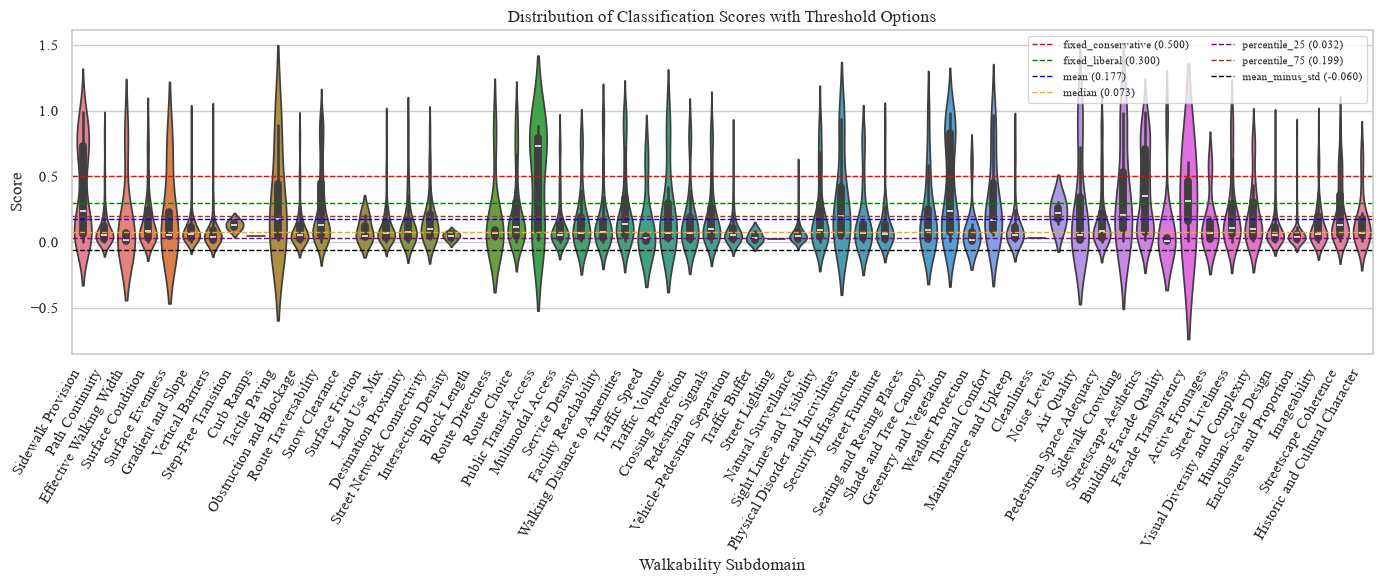

In [10]:
# Calculate statistical thresholds
all_scores = []
for scores in domain_scores.values():
    all_scores.extend([s for s in scores if not np.isnan(s)])

# Calculate various statistical thresholds
thresholds = {
    "fixed_conservative": 0.5,  # Standard fixed threshold
    "fixed_liberal": 0.3,  # More inclusive fixed threshold
    "mean": np.mean(all_scores),  # Average of all scores
    "median": np.median(all_scores),  # Median (50th percentile)
    "percentile_25": np.percentile(all_scores, 25),  # 25th percentile
    "percentile_75": np.percentile(all_scores, 75),  # 75th percentile
    "mean_minus_std": np.mean(all_scores) - np.std(all_scores),  # Lower statistical bound
}

# Display calculated thresholds
print("\n📏 Possible Thresholds:")
for name, value in thresholds.items():
    print(f"  - {name}: {value:.4f}")

# Let's see how many dimensions would be assigned with each threshold
print("\n📊 Subdomains Assigned per Abstract with Different Thresholds:")
for name, threshold in thresholds.items():
    domains_per_abstract = []

    # Iterate through the DataFrame rows
    for _, row in df_filtered.iterrows():
        if 'classification_scores' in row and not pd.isna(row['classification_scores']).any():
            # Count subdomains above threshold
            assigned_domains = sum(1 for score in row['classification_scores'] if score >= threshold)
            domains_per_abstract.append(assigned_domains)

    avg_domains = np.mean(domains_per_abstract) if domains_per_abstract else 0
    print(f"  - {name} (threshold={threshold:.4f}): {avg_domains:.2f} subdomains per abstract")

# Plot threshold lines on the violin plot
plt.figure(figsize=(14, 6))
sns.violinplot(data=scores_df)
plt.xticks(rotation=60, ha="right")
plt.title("Distribution of Classification Scores with Threshold Options")
plt.ylabel("Score")
plt.xlabel("Walkability Subdomain")

# Add horizontal lines for thresholds with different colors
colors = ["red", "green", "blue", "orange", "purple", "brown", "black"]
for (name, threshold), color in zip(thresholds.items(), colors):
    plt.axhline(y=threshold, color=color, linestyle="--", linewidth=1, label=f"{name} ({threshold:.3f})")

plt.legend(loc="upper right", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## Calibrating the Threshold Against `real.json`

Instead of a fixed threshold picked in advance, this calibrates against the labeled
validation set already used for the inclusion/exclusion screening step
(`real.json`). One caveat matters here: `label == 0` in `real.json` means the article
was *excluded during screening* -- for reasons including not using a sensor at all,
measuring pedestrian behavior instead of a built-environment attribute, or targeting a
different construct (see the adjudication rules used in the screening notebook). It
does **not** mean "does not discuss any walkability dimension" -- an excluded article
can still discuss safety or comfort topically without a sensor measuring it. So
`label == 0` is not treated as a clean negative class here, and precision/WSS are not
computed against it -- only `label == 1` (confirmed sensor-based walkability-dimension
articles) is used, to calibrate recall: the threshold below which a target fraction of
*known-relevant* articles would still receive at least one macro dimension.

This directly targets the concern raised by the 0.5 fixed threshold leaving 75% of the
corpus with no dimension assigned: a gap that large is not fully explained by the
screening step's own false-discovery rate (roughly 40%, from the WSS@95 calibration
used there) -- some of the gap is legitimate (screening false positives correctly
falling out here too), but the rest is the dimension classifier missing dimensions
that are actually present, an artifact of many subdomain labels competing for
probability mass in multi-label zero-shot classification.

In [11]:
# Load the same validation set used for inclusion/exclusion screening.
real_df = pd.read_json("../model/dataset/real.json")

# Same field priority used in the corpus (contribution first) — calibration
REAL_TEXT_FIELD_CANDIDATES = ["contribution", "abstract", "introduction", "text", "contribution_text"]
REAL_LABEL_FIELD_CANDIDATES = ["label", "is_walkability_related", "walkability", "y", "class"]
POSITIVE_LABEL_VALUES = {1, "1", True, "true", "True", "positive", "Positive", "yes", "Yes",
                         "Sensing of walkability dimension", "sensing of walkability dimension"}

def get_text(record, field_candidates=REAL_TEXT_FIELD_CANDIDATES):
    for field in field_candidates:
        val = record.get(field)
        if isinstance(val, str) and val.strip():
            return val.strip()
    return None

def get_label(record, field_candidates=REAL_LABEL_FIELD_CANDIDATES, positive_values=POSITIVE_LABEL_VALUES):
    for field in field_candidates:
        if field in record and record[field] is not None:
            return 1 if record[field] in positive_values else 0
    return None

real_df["text"] = real_df.apply(lambda r: get_text(r.to_dict()), axis=1)
real_df["label"] = real_df.apply(lambda r: get_label(r.to_dict()), axis=1)
real_df = real_df.dropna(subset=["text", "label"]).reset_index(drop=True)
real_df["label"] = real_df["label"].astype(int)

print(f"Loaded {len(real_df)} labeled records from real.json "
      f"({real_df['label'].sum()} positive / confirmed sensor-based walkability-dimension articles)")

Loaded 100 labeled records from real.json (45 positive / confirmed sensor-based walkability-dimension articles)


In [12]:
# Classify real.json with the same hypotheses used for the main corpus (v5: includes
# the negative-anchor pass).
tqdm.pandas(desc="Classifying real.json for dimension calibration")

def classify_and_get_macro_scores(text):
    sub_res = classifier(
        text,
        candidate_labels=SUBDOMAIN_LABEL_LIST,
        hypothesis_template=SUBDOMAIN_HYPOTHESIS,
        multi_label=True,
    )
    macro_res = classifier(
        text,
        candidate_labels=MACRO_LABEL_LIST,
        hypothesis_template=MACRO_HYPOTHESIS,
        multi_label=True,
    )
    subdomain_scores = {
        label_text_to_subdomain[l]: s for l, s in zip(sub_res["labels"], sub_res["scores"])
    }
    macro_direct = {
        macro_text_to_name[l]: s for l, s in zip(macro_res["labels"], macro_res["scores"])
    }
    # v6: records which negative anchor fired, not just the score -- needed
    # to confirm directly (not by aggregate inference) whether the Rule 4 anchor correction
    # fixed the problem or whether there was still undue firing from the other three.
    neg_res = classifier(
        text,
        candidate_labels=DIMENSION_HARD_NEGATIVES,
        hypothesis_template=DIMENSION_HARD_NEGATIVE_HYPOTHESIS,
        multi_label=True,
    )
    negative_score = max(neg_res["scores"])
    negative_label = neg_res["labels"][neg_res["scores"].index(negative_score)]
    return (macro_scores_from_parts(subdomain_scores, macro_direct, negative_score),
            negative_score, negative_label)

_results = real_df["text"].progress_apply(classify_and_get_macro_scores)
real_df["macro_scores"] = _results.apply(lambda t: t[0])
real_df["negative_score"] = _results.apply(lambda t: t[1])
real_df["negative_label"] = _results.apply(lambda t: t[2])

# Best (highest) macro-dimension score per record -- this is what determines whether
# a record would receive at least one dimension at a given threshold.
real_df["best_dimension_score"] = real_df["macro_scores"].apply(lambda s: max(s.values()))

# Diagnostic: does the negative anchor fire on any confirmed positive? If so, in how many?
# This measures the recall cost imposed by the margin on the gold set itself.
pos = real_df[real_df["label"] == 1]
pos_high_negative = (pos["negative_score"] > NEGATIVE_ANCHOR_FIRE_THRESHOLD).sum()
print(f"\nConfirmed positives with negative_score above threshold "
      f"({NEGATIVE_ANCHOR_FIRE_THRESHOLD:.3f}): {pos_high_negative}/{len(pos)} "
      f"({pos_high_negative/max(len(pos),1)*100:.1f}%)")
if pos_high_negative:
    flagged = pos[pos["negative_score"] > NEGATIVE_ANCHOR_FIRE_THRESHOLD]
    print("Distribution by fired anchor among the incorrectly rejected positives:")
    print(flagged["negative_label"].str.slice(0, 70).value_counts().to_string())
    print("\nTitles:")
    for t, lbl in zip(flagged["text"].head(15), flagged["negative_label"].head(15)):
        print(f"  - [{lbl[:45]}...] {t[:90]}")


Classifying real.json for dimension calibration: 100%|██████████| 100/100 [27:09<00:00, 16.29s/it]


Confirmed positives with negative_score above threshold (0.220): 19/45 (42.2%)
Distribution by fired anchor among incorrectly rejected positives:
negative_label
This study's primary research question concerns physical activity, hea    15
This study uses a pre-existing walkability index, audit score, or envi     2
This study develops or evaluates a navigation, routing, or delivery sy     2

Titles:
  - [This study's primary research question concer...] ALF–Score—A novel approach to build a predictive network–based walkability scoring system.
  - [This study's primary research question concer...] Wearable Sensor-based Walkability Assessment at Ferry Terminal Using Machine Learning: A C
  - [This study uses a pre-existing walkability in...] The mediating role of visual behavior in perceived walkability evaluation. Past studies us
  - [This study's primary research question concer...] Association of street greenery and physical activity in older adults: A novel study using 
  - [This stud

In [13]:
# Threshold calibration: find the score below which TARGET_DIMENSION_RECALL of the
# label == 1 (confirmed) articles would still receive at least one macro-dimension.
#
# v5: introducing the negative margin changes the score scale -- it can now be
# negative (positive signal smaller than the strongest negative anchor). The calibration logic
# using a percentile cutoff does not assume non-negativity, so it continues
# to work as-is; only the resulting `CALIBRATED_THRESHOLD` may be negative,
# which is expected and correct -- it means even a weak positive signal exceeds a
# weak negative margin sufficiently for the hardest confirmed positives in the gold set.
#
# v4 (revised): moved back from 0.80 to 0.70. The first attempt at 0.80 (threshold
# absolute 0.0608) was audited in two ways: (a) a sample of 50 records
# previously without dimensions -- 32 recovered, confirming that switching the field
# (contribution instead of introduction) already delivers most of the recall gain;
# (b) a sample of 25 records in the marginal band [0.0608, 0.13] -- only 8/25 (32%)
# were genuine dimension measurements; 15/25 (60%) were false positives, and the dominant pattern
# was exactly Rule 4 (behavior/physical activity treated as an outcome, not a dimension)
# leaking back in when the threshold was too low -- the same dominant false-positive pattern
# already documented in the project. 0.70 preserves most of the recall gain from the field swap
# without reopening that precision gap.
TARGET_DIMENSION_RECALL = 0.70
positive_scores = real_df.loc[real_df["label"] == 1, "best_dimension_score"].sort_values()
n_positive = len(positive_scores)
# Guard: if there are no confirmed positives, avoid iloc out-of-bounds and pick a sensible default.
if n_positive == 0:
    CALIBRATED_THRESHOLD = 0.5
    achieved_recall = 0.0
    fixed_recall = float('nan')
    print("Warning: no confirmed positives found in real.json; ", end='')
    print(" defaulting calibrated threshold to 0.5 and skipping calibration.")
else:
    # Lowest score such that at least TARGET_DIMENSION_RECALL of positives are >= it.
    cutoff_idx = int(np.floor((1 - TARGET_DIMENSION_RECALL) * n_positive))
    cutoff_idx = max(0, min(cutoff_idx, n_positive - 1))
    CALIBRATED_THRESHOLD = float(positive_scores.iloc[cutoff_idx])
    achieved_recall = float((positive_scores >= CALIBRATED_THRESHOLD).mean())
    fixed_recall = float((positive_scores >= 0.5).mean())

print(f"n confirmed positives in real.json: {n_positive}")
print(f"Calibrated threshold: {CALIBRATED_THRESHOLD:.4f}")
print(f"Achieved recall among confirmed positives at this threshold: {achieved_recall:.3f}")
print(f"(compare: fixed_conservative=0.5000 achieved recall {fixed_recall:.3f}, among the same confirmed positives)")
print(f"(compare: v3 used TARGET_DIMENSION_RECALL=0.70; threshold and score are not comparable "
      f"across versions because the input text field changed)")


n confirmed positives in real.json: 45
Calibrated threshold: -0.0044
Achieved recall among confirmed positives at this threshold: 0.711
(compare: fixed_conservative=0.5000 achieved recall 0.178, among the same confirmed positives)
(compare: v3 usava TARGET_DIMENSION_RECALL=0.70; threshold e score não são comparáveis entre versões porque o campo de texto de entrada mudou)


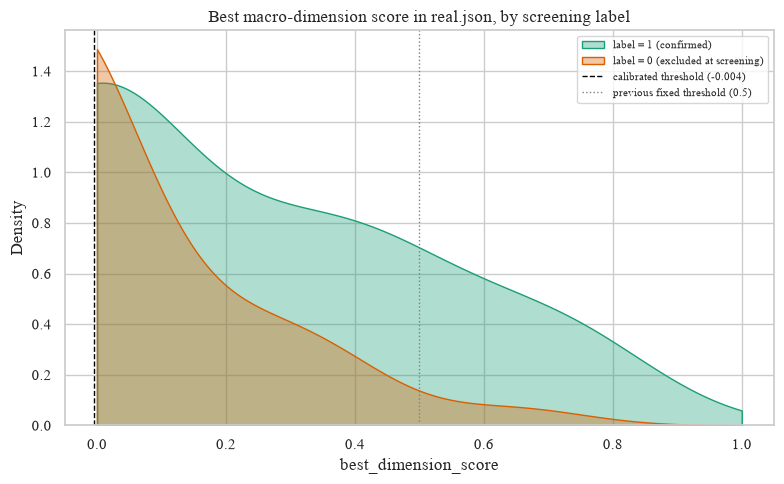

In [14]:
# Diagnostic plot only -- label == 0 is not a clean negative class for this task
# (see note above), so this is not used to pick a precision-optimal cut, just to see
# whether confirmed-positive and excluded articles look different at all.
fig, ax = plt.subplots(figsize=(8, 5))
for label_value, label_name, color in [(1, "label = 1 (confirmed)", "#1b9e77"),
                                        (0, "label = 0 (excluded at screening)", "#d95f02")]:
    subset = real_df.loc[real_df["label"] == label_value, "best_dimension_score"]
    sns.kdeplot(subset, ax=ax, fill=True, alpha=0.35, color=color, label=label_name, clip=(0, 1))
ax.axvline(CALIBRATED_THRESHOLD, color="black", linestyle="--", linewidth=1,
           label=f"calibrated threshold ({CALIBRATED_THRESHOLD:.3f})")
ax.axvline(0.5, color="gray", linestyle=":", linewidth=1, label="previous fixed threshold (0.5)")
ax.set_title("Best macro-dimension score in real.json, by screening label")
ax.set_xlabel("best_dimension_score")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
# Same subdomain-level violin plot as before, now with the calibrated threshold
# (from real.json) marked instead of the earlier arbitrary options -- shows whether
# a single threshold is reasonable across all 40 subdomains, or whether some
# subdomains are systematically higher/lower scoring than others.
plt.figure(figsize=(14, 6))
sns.violinplot(data=scores_df)
plt.xticks(rotation=60, ha="right")
plt.title("Distribution of Classification Scores with the Calibrated Threshold")
plt.ylabel("Score")
plt.xlabel("Walkability Subdomain")

plt.axhline(y=CALIBRATED_THRESHOLD, color="black", linestyle="--", linewidth=1.5,
            label=f"calibrated threshold ({CALIBRATED_THRESHOLD:.4f})")
plt.axhline(y=0.5, color="gray", linestyle=":", linewidth=1,
            label="previous fixed threshold (0.5)")

plt.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## Assign Macro Walkability Dimensions

In [16]:
from collections import Counter

def assign_macro_dimensions_to_df(df, dimension_hierarchy, score_threshold=0.5):
    """Assign macro-dimensions from the combined macro score.

    Two changes relative to v2:
    1. The macro score is already computed (`macro_scores`), combining the best verified subdomain
       with the direct macro verification — instead of just the maximum across
       the subdomains.
    2. When re-aggregation is needed from subdomains (records without `macro_scores`,
       due to a batch failure), the exact mapping `subdomain_to_macro` is used instead of
       the v2 substring matching with `break`.
    """
    all_macro_dimensions = []

    for _, row in df.iterrows():
        scores = row.get("macro_scores")

        if not isinstance(scores, dict):
            # Fallback: re-aggregates the subdomains with exact mapping.
            row_labels = row.get("classification_labels")
            row_scores = row.get("classification_scores")
            if row_labels is None or row_scores is None:
                all_macro_dimensions.append([])
                continue
            dimension_scores = {macro: 0.0 for macro in dimension_hierarchy}
            for label, score in zip(row_labels, row_scores):
                macro = subdomain_to_macro.get(label)
                if macro is not None:
                    dimension_scores[macro] = max(dimension_scores[macro], score)
            scores = dimension_scores

        assigned = [macro for macro, score in scores.items() if score >= score_threshold]
        all_macro_dimensions.append(assigned)

    df = df.copy()
    df["macro_dimensions"] = all_macro_dimensions
    return df


# Assign macro walkability dimensions using the threshold calibrated against
# real.json above. Adjust TARGET_DIMENSION_RECALL in the calibration section
# (not this value directly) if a different recall trade-off is preferred.
#
# NOTE: the threshold must be recalibrated from scratch in v3. The score scale changed
# (mean of two signals, measurement hypothesis instead of topic), so any value
# inherited from v2 is not comparable.
CONFIG_SCORE_THRESHOLD = CALIBRATED_THRESHOLD

df_with_domains = assign_macro_dimensions_to_df(
    df_filtered, walkability_dimensions, score_threshold=CONFIG_SCORE_THRESHOLD
)

domain_counts = Counter()
for dims in df_with_domains['macro_dimensions']:
    domain_counts.update(dims)

print("\n📊 Dimension Distribution:")
for domain, count in domain_counts.most_common():
    print(f"  - {domain}: {count} abstracts")

avg_domains = np.mean([len(d) for d in df_with_domains['macro_dimensions']])
multi_domain = sum(1 for d in df_with_domains['macro_dimensions'] if len(d) > 1)
zero_domain = sum(1 for d in df_with_domains['macro_dimensions'] if len(d) == 0)
print(f"\nAverage dimensions per abstract: {avg_domains:.2f}")
print(f"Abstracts with multiple dimensions: {multi_domain} ({multi_domain/len(df_with_domains)*100:.2f}%)")
print(f"Abstracts with NO dimension assigned: {zero_domain} ({zero_domain/len(df_with_domains)*100:.2f}%)")

# Diagnostic of the macro-check effect: how many assignments v2 would have made
# (using only the maximum subdomain score) and which v3 rejects for lack of the second signal.
v2_style = 0
for _, row in df_with_domains.iterrows():
    subs = dict(zip(row["classification_labels"], row["classification_scores"]))
    for macro, sublist in walkability_dimensions.items():
        if max((subs.get(s, 0.0) for s in sublist), default=0.0) >= CONFIG_SCORE_THRESHOLD:
            v2_style += 1
v3_total = sum(len(d) for d in df_with_domains['macro_dimensions'])
print(f"\nAssignments in v2 style (best subdomain only): {v2_style}")
print(f"Assignments in v3 (with macro verification):          {v3_total}")
print(f"Difference: {v2_style - v3_total} fewer assignments "
      f"— candidates for false positives due to isolated subdomain triggers")



📊 Dimension Distribution:
  - Feasibility: 345 abstracts
  - Comfort: 296 abstracts
  - Pleasurability: 264 abstracts
  - Accessibility: 262 abstracts
  - Safety: 218 abstracts

Average dimensions per abstract: 1.60
Abstracts with multiple dimensions: 364 (41.98%)
Abstracts with NO dimension assigned: 393 (45.33%)

Assignments in v2 style (best subdomain only): 4335
Assignments in v3 (with macro verification):          1385
Difference: 2950 atribuições a menos — candidatas a falso positivo por subdomain isolado


# Visualize Dimension Distribution
Create a bar chart showing how many abstracts were assigned to each macro walkability dimension.

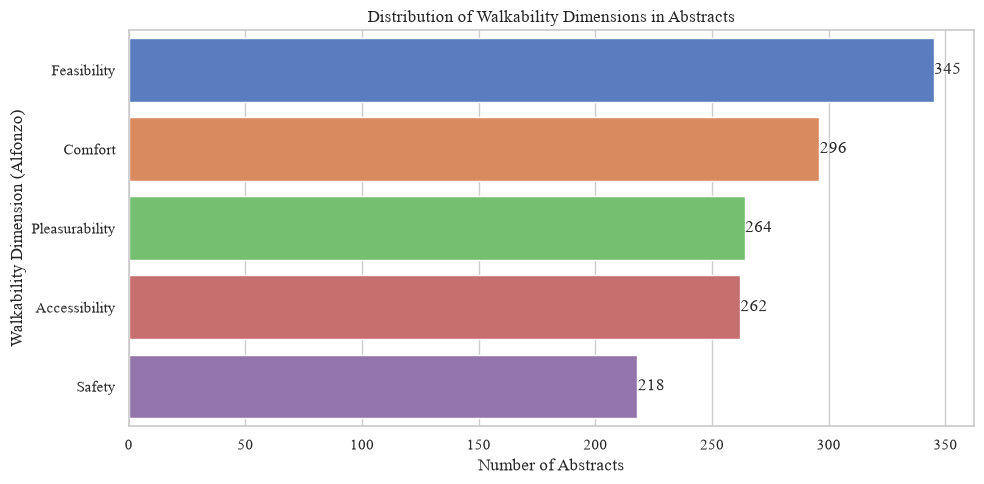

In [17]:
# Plot the distribution of dimensions using a matte color palette
palette = sns.color_palette("muted", n_colors=len(domain_counts))

# Create the dimension and count lists
dimensions_list = [domain for domain, count in domain_counts.most_common()]
counts = [count for domain, count in domain_counts.most_common()]

# Create a bar plot of dimension counts
plt.figure(figsize=(10, 5))
sns.barplot(
    x=counts,
    y=dimensions_list,
    hue=dimensions_list,
    palette=palette,
    legend=False,
)
plt.xlabel("Number of Abstracts")
plt.ylabel("Walkability Dimension (Alfonzo)")
plt.title("Distribution of Walkability Dimensions in Abstracts")

# Add value labels to the end of each bar
for i, count in enumerate(counts):
    plt.text(count + 0.2, i, str(count), va="center")

plt.tight_layout()

# Save the plot
# plt.savefig("../data/06_2_dimension_distribution.png")

plt.show()

# Sensing Modality × Alfonzo Dimension

A quick cross-tabulation of which sensor/technology types (if already classified — e.g. by
the companion sensor-type notebook) co-occur with which walkability dimensions, mirroring
the crosstab already built in the corpus analysis notebook. Skipped automatically if a
sensor-type column isn't present yet.

In [18]:
SENSOR_COLUMN_CANDIDATES = ["sensor_type", "macro_sensor_types", "technology_type"]
sensor_col = next((c for c in SENSOR_COLUMN_CANDIDATES if c in df_with_domains.columns), None)

if sensor_col is None:
    print("No sensor-type column found yet (expected one of "
          f"{SENSOR_COLUMN_CANDIDATES}) — run the sensor-type classification notebook "
          "first, merge its output in by DOI, then re-run this cell for the crosstab.")
else:
    exploded = df_with_domains.explode('macro_dimensions').explode(sensor_col)
    crosstab = pd.crosstab(exploded[sensor_col], exploded['macro_dimensions'])
    display(crosstab)

    plt.figure(figsize=(10, 6))
    sns.heatmap(crosstab, annot=True, fmt="d", cmap="Blues")
    plt.title("Sensing Modality × Alfonzo Dimension")
    plt.tight_layout()
    plt.show()

No sensor-type column found yet (expected one of ['sensor_type', 'macro_sensor_types', 'technology_type']) — run the sensor-type classification notebook first, merge its output in by DOI, then re-run this cell for the crosstab.


# Filter Articles with no Dimension Assigned

In [19]:
no_domain_mask = df_with_domains['macro_dimensions'].apply(lambda x: len(x) == 0)
no_domain_df = df_with_domains[no_domain_mask]

# Remove articles with no assigned macro dimension from the DataFrame
df_with_domains = df_with_domains[~no_domain_mask].copy()
df_with_domains = df_with_domains.reset_index(drop=True)
print(f"\nFiltered DataFrame size: {len(df_with_domains)} articles with assigned dimensions")


Filtered DataFrame size: 474 articles with assigned dimensions


# Save the Results

In [20]:
# Save the DataFrame with macro walkability dimensions to a JSON file
df_with_domains.to_json("../data/06_1_classified_walkability_dimensions.json", orient="records", indent=4)

# Save the dataframe with no assigned dimensions to a JSON file
no_domain_df.to_json("../data/06_1_no_assigned_dimensions.json", orient="records", indent=4)

print(f"Saved:\n  ../data/06_1_classified_walkability_dimensions.json ({len(df_with_domains)} records)"
      f"\n  ../data/06_1_no_assigned_dimensions.json ({len(no_domain_df)} records)")

Saved:
  ../data/06_1_classified_walkability_dimensions.json (474 records)
  ../data/06_1_no_assigned_dimensions.json (393 records)


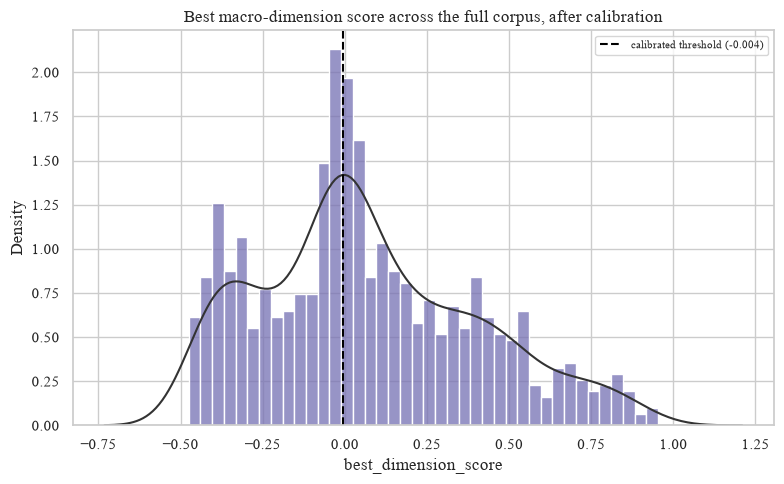

Share of corpus above the calibrated threshold: 54.7%


In [21]:
# Post-calibration diagnostic: distribution of each abstract's best macro-dimension
# score across the full corpus, with the calibrated threshold marked.
corpus_best_scores = df_filtered["macro_scores"].apply(lambda s: max(s.values()))

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(corpus_best_scores, bins=40, ax=ax, color="#7570b3", stat="density")
sns.kdeplot(corpus_best_scores, ax=ax, color="#333333", linewidth=1.5)
ax.axvline(CONFIG_SCORE_THRESHOLD, color="black", linestyle="--", linewidth=1.5,
           label=f"calibrated threshold ({CONFIG_SCORE_THRESHOLD:.3f})")
ax.set_title("Best macro-dimension score across the full corpus, after calibration")
ax.set_xlabel("best_dimension_score")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

above = (corpus_best_scores >= CONFIG_SCORE_THRESHOLD).mean()
print(f"Share of corpus above the calibrated threshold: {above*100:.1f}%")
